<a href="https://colab.research.google.com/github/RozieKii/localTest/blob/main/embeddings_deep_dive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
import re
import numpy as np

class ExampleClass:
    """
    Demonstrate word-context relationships used in embedding methods.
    This is a simplified illustration, not a trained Word2Vec or GloVe model.
    """

    def __init__(self):
        self.data = []
        self.word_counts = {}
        self.co_occurrence = {}

    def process(self, input_data):
        """Tokenize text and count words and neighboring word pairs."""
        if not isinstance(input_data, str):
            raise TypeError("Input data must be a string.")

        words = re.findall(r"\b\w+\b", input_data.lower())

        if not words:
            raise ValueError("Input text must contain at least one word.")

        self.data = words

        # Count each word
        for word in words:
            self.word_counts[word] = self.word_counts.get(word, 0) + 1

        # Count neighboring word pairs
        for i in range(len(words) - 1):
            pair = (words[i], words[i + 1])
            self.co_occurrence[pair] = (
                self.co_occurrence.get(pair, 0) + 1
            )

        return {
            "words": words,
            "word_counts": self.word_counts.copy(),
            "co_occurrence": {
                f"{first} -> {second}": count
                for (first, second), count in self.co_occurrence.items()
            }
        }


# Test the class
example = ExampleClass()

sample_text = (
    "AI helps people learn. AI helps people grow."
)

result = example.process(sample_text)

print("Words:", result["words"])
print("\nWord counts:")
print(result["word_counts"])

print("\nNeighboring word pairs:")
print(result["co_occurrence"])

Words: ['ai', 'helps', 'people', 'learn', 'ai', 'helps', 'people', 'grow']

Word counts:
{'ai': 2, 'helps': 2, 'people': 2, 'learn': 1, 'grow': 1}

Neighboring word pairs:
{'ai -> helps': 2, 'helps -> people': 2, 'people -> learn': 1, 'learn -> ai': 1, 'people -> grow': 1}


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
import re
from collections import Counter

class BasicEmbeddingAnalyzer:
    """
    Analyze word frequencies and neighboring word relationships.
    This demonstrates a foundation for understanding embeddings.
    """

    def process(self, input_data):
        """Tokenize text and calculate word and pair frequencies."""

        if not isinstance(input_data, str):
            raise TypeError("Input must be a string.")

        words = re.findall(r"\b\w+\b", input_data.lower())

        if not words:
            raise ValueError("Input must contain at least one word.")

        word_counts = Counter(words)

        # Count neighboring pairs
        pairs = Counter(
            (words[i], words[i + 1])
            for i in range(len(words) - 1)
        )

        return {
            "words": words,
            "word_counts": dict(word_counts),
            "co_occurrence": {
                f"{first} -> {second}": count
                for (first, second), count in pairs.items()
            }
        }


# -------------------------
# Test 1: Normal text
# -------------------------
analyzer = BasicEmbeddingAnalyzer()
result = analyzer.process("AI helps people learn. AI helps people grow.")

print("Test 1: Normal text")
print(result)

assert result["word_counts"]["ai"] == 2
assert result["word_counts"]["helps"] == 2
assert result["co_occurrence"]["ai -> helps"] == 2
print("✅ Test 1 passed")

# -------------------------
# Test 2: Single word
# -------------------------
result = analyzer.process("Python")

assert result["words"] == ["python"]
assert result["co_occurrence"] == {}
print("✅ Test 2 passed: Single word")

# -------------------------
# Test 3: Empty input
# -------------------------
try:
    analyzer.process("")
except ValueError as error:
    print("✅ Test 3 passed:", error)
else:
    raise AssertionError("Expected ValueError for empty input")

# -------------------------
# Test 4: Wrong input type
# -------------------------
try:
    analyzer.process(123)
except TypeError as error:
    print("✅ Test 4 passed:", error)
else:
    raise AssertionError("Expected TypeError for non-string input")

# -------------------------
# Test 5: Punctuation only
# -------------------------
try:
    analyzer.process("!!! ???")
except ValueError as error:
    print("✅ Test 5 passed:", error)
else:
    raise AssertionError("Expected ValueError for punctuation-only input")

print("\n🎉 All Exercise 1 tests passed!")

Test 1: Normal text
{'words': ['ai', 'helps', 'people', 'learn', 'ai', 'helps', 'people', 'grow'], 'word_counts': {'ai': 2, 'helps': 2, 'people': 2, 'learn': 1, 'grow': 1}, 'co_occurrence': {'ai -> helps': 2, 'helps -> people': 2, 'people -> learn': 1, 'learn -> ai': 1, 'people -> grow': 1}}
✅ Test 1 passed
✅ Test 2 passed: Single word
✅ Test 3 passed: Input must contain at least one word.
✅ Test 4 passed: Input must be a string.
✅ Test 5 passed: Input must contain at least one word.

🎉 All Exercise 1 tests passed!


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
import numpy as np
import json
from typing import List, Any, Dict
from collections import Counter

def advanced_function(
    data: List[Any],
    embedding_dim: int = 5,
    **kwargs
) -> Dict[str, Any]:
    """
    Build simple numerical vectors for words in the input text.

    Note: These are randomly initialized demonstration vectors,
    not embeddings learned through Word2Vec or GloVe training.
    """

    if not isinstance(data, list):
        raise TypeError("data must be a list of strings.")

    if not data:
        raise ValueError("data cannot be empty.")

    if not all(isinstance(item, str) for item in data):
        raise TypeError("Every item in data must be a string.")

    if not isinstance(embedding_dim, int) or isinstance(embedding_dim, bool):
        raise TypeError("embedding_dim must be an integer.")

    if embedding_dim <= 0:
        raise ValueError("embedding_dim must be greater than zero.")

    seed = kwargs.get("seed", 42)
    rng = np.random.default_rng(seed)

    # Split text into lowercase words
    words = []
    for sentence in data:
        words.extend(sentence.lower().split())

    if not words:
        raise ValueError("The input must contain at least one word.")

    vocabulary = sorted(set(words))

    # Create one numerical vector for each unique word
    embeddings = {
        word: rng.normal(0, 1, embedding_dim).round(3).tolist()
        for word in vocabulary
    }

    return {
        "processed": len(data),
        "vocabulary_size": len(vocabulary),
        "embedding_dimension": embedding_dim,
        "word_counts": dict(Counter(words)),
        "embeddings": embeddings
    }


# Example usage
sample_data = [
    "AI helps people learn",
    "AI helps people grow",
    "People learn AI"
]

output = advanced_function(sample_data, embedding_dim=5)

print(json.dumps(output, indent=2))

{
  "processed": 3,
  "vocabulary_size": 5,
  "embedding_dimension": 5,
  "word_counts": {
    "ai": 3,
    "helps": 2,
    "people": 3,
    "learn": 2,
    "grow": 1
  },
  "embeddings": {
    "ai": [
      0.305,
      -1.04,
      0.75,
      0.941,
      -1.951
    ],
    "grow": [
      -1.302,
      0.128,
      -0.316,
      -0.017,
      -0.853
    ],
    "helps": [
      0.879,
      0.778,
      0.066,
      1.127,
      0.468
    ],
    "learn": [
      -0.859,
      0.369,
      -0.959,
      0.878,
      -0.05
    ],
    "people": [
      -0.185,
      -0.681,
      1.223,
      -0.155,
      -0.428
    ]
  }
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:

import re
import numpy as np
from collections import Counter
from typing import List, Any, Dict


def build_embeddings(
    data: List[str],
    embedding_dim: int = 5,
    seed: int = 42
) -> Dict[str, Any]:
    """
    Analyze text and create demonstration vectors for each unique word.
    These vectors are randomly initialized, not trained Word2Vec embeddings.
    """

    # 1. Validate parameters
    if not isinstance(data, list):
        raise TypeError("data must be a list of strings.")

    if not data:
        raise ValueError("data cannot be empty.")

    if not all(isinstance(sentence, str) for sentence in data):
        raise TypeError("Every item in data must be a string.")

    if not isinstance(embedding_dim, int) or isinstance(embedding_dim, bool):
        raise TypeError("embedding_dim must be an integer.")

    if embedding_dim <= 0:
        raise ValueError("embedding_dim must be greater than zero.")

    if not isinstance(seed, int) or isinstance(seed, bool):
        raise TypeError("seed must be an integer.")

    # 2. Tokenize text and validate its contents
    words = []
    for sentence in data:
        words.extend(re.findall(r"\b\w+\b", sentence.lower()))

    if not words:
        raise ValueError("The input text must contain at least one word.")

    # 3. Count words and neighboring word pairs
    word_counts = Counter(words)

    pairs = Counter(
        (words[i], words[i + 1])
        for i in range(len(words) - 1)
    )

    # 4. Create a vocabulary and demonstration vectors
    vocabulary = sorted(set(words))
    rng = np.random.default_rng(seed)

    embeddings = {
        word: rng.normal(0, 1, embedding_dim).round(3).tolist()
        for word in vocabulary
    }

    # 5. Return the combined results
    return {
        "sentences_processed": len(data),
        "vocabulary_size": len(vocabulary),
        "embedding_dimension": embedding_dim,
        "word_counts": dict(word_counts),
        "co_occurrence": {
            f"{first} -> {second}": count
            for (first, second), count in pairs.items()
        },
        "embeddings": embeddings
    }


# TEST 1: Normal input
print("TEST 1: Normal input")
result = build_embeddings([
    "AI helps people learn.",
    "AI helps people grow."
])

print("Sentences:", result["sentences_processed"])
print("Vocabulary:", result["vocabulary_size"])
print("Word counts:", result["word_counts"])
print("Word pairs:", result["co_occurrence"])
print("AI vector:", result["embeddings"]["ai"])
assert result["word_counts"]["ai"] == 2
assert result["co_occurrence"]["ai -> helps"] == 2
assert len(result["embeddings"]["ai"]) == 5
print("Passed!\n")


# TEST 2: Custom embedding dimension
print("TEST 2: Custom embedding dimension")
result = build_embeddings(["Python is useful"], embedding_dim=3)
assert len(result["embeddings"]["python"]) == 3
print("Passed! Each vector has 3 numbers.\n")


# TEST 3: Empty list
print("TEST 3: Empty input")
try:
    build_embeddings([])
except ValueError as error:
    print("Passed!", error)
else:
    raise AssertionError("Expected ValueError")


# TEST 4: Wrong input type
print("\nTEST 4: Wrong input type")
try:
    build_embeddings("This is not a list")
except TypeError as error:
    print("Passed!", error)
else:
    raise AssertionError("Expected TypeError")


# TEST 5: Invalid item in the list
print("\nTEST 5: Invalid list item")
try:
    build_embeddings(["AI is useful", 123])
except TypeError as error:
    print("Passed!", error)
else:
    raise AssertionError("Expected TypeError")


# TEST 6: Invalid embedding dimension
print("\nTEST 6: Invalid dimension")
try:
    build_embeddings(["AI is useful"], embedding_dim=0)
except ValueError as error:
    print("Passed!", error)
else:
    raise AssertionError("Expected ValueError")


# TEST 7: Punctuation only
print("\nTEST 7: Punctuation only")
try:
    build_embeddings(["!!! ???"])
except ValueError as error:
    print("Passed!", error)
else:
    raise AssertionError("Expected ValueError")


print("\nAll 7 tests passed!")


TEST 1: Normal input
Sentences: 2
Vocabulary: 5
Word counts: {'ai': 2, 'helps': 2, 'people': 2, 'learn': 1, 'grow': 1}
Word pairs: {'ai -> helps': 2, 'helps -> people': 2, 'people -> learn': 1, 'learn -> ai': 1, 'people -> grow': 1}
AI vector: [0.305, -1.04, 0.75, 0.941, -1.951]
Passed!

TEST 2: Custom embedding dimension
Passed! Each vector has 3 numbers.

TEST 3: Empty input
Passed! data cannot be empty.

TEST 4: Wrong input type
Passed! data must be a list of strings.

TEST 5: Invalid list item
Passed! Every item in data must be a string.

TEST 6: Invalid dimension
Passed! embedding_dim must be greater than zero.

TEST 7: Punctuation only
Passed! The input text must contain at least one word.

All 7 tests passed!


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

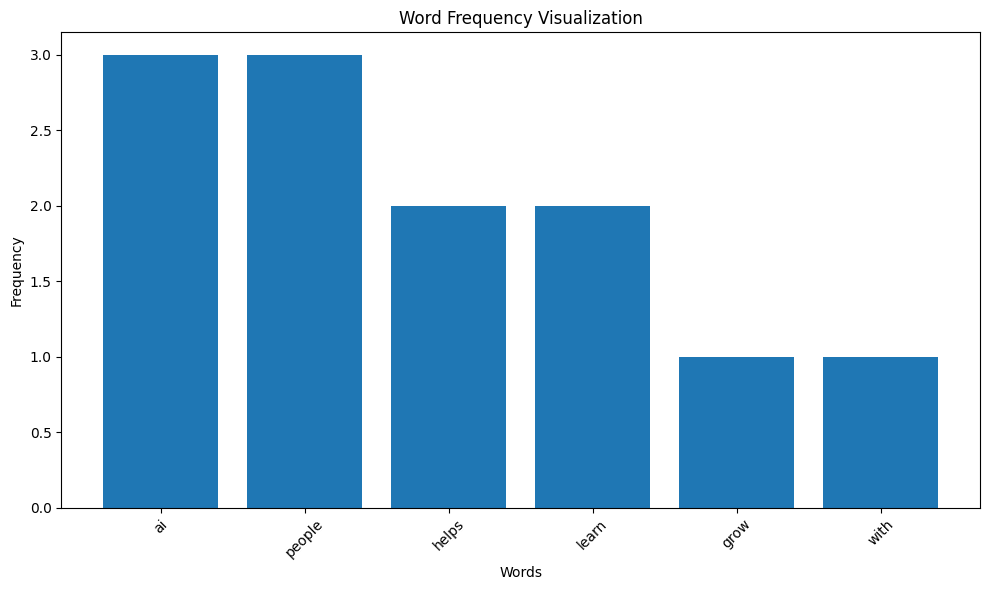

Word frequencies: {'ai': 3, 'helps': 2, 'people': 3, 'learn': 2, 'grow': 1, 'with': 1}


In [6]:

import matplotlib.pyplot as plt
import re
from collections import Counter
from typing import List, Any


def visualize_results(data: List[Any]):
    """
    Visualize word frequencies in a list of text strings.
    """

    # Validate the input
    if not isinstance(data, list):
        raise TypeError("data must be a list of strings.")

    if not data:
        raise ValueError("data cannot be empty.")

    if not all(isinstance(sentence, str) for sentence in data):
        raise TypeError("Every item in data must be a string.")

    # Extract words
    words = []
    for sentence in data:
        words.extend(re.findall(r"\b\w+\b", sentence.lower()))

    if not words:
        raise ValueError("The input must contain at least one word.")

    # Count word frequencies
    word_counts = Counter(words)
    most_common = word_counts.most_common()

    labels = [word for word, count in most_common]
    counts = [count for word, count in most_common]

    # Create the chart
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(labels, counts)

    ax.set_title("Word Frequency Visualization")
    ax.set_xlabel("Words")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

    return dict(word_counts)


# Example
sample_data = [
    "AI helps people learn",
    "AI helps people grow",
    "People learn with AI"
]

frequencies = visualize_results(sample_data)
print("Word frequencies:", frequencies)


### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation


TEST 1: Text processing
Sentences processed: 3
Vocabulary size: 8
Word counts: {'i': 3, 'want': 3, 'to': 3, 'learn': 2, 'ai': 1, 'build': 2, 'pathpilot': 1, 'and': 1}
Neighboring pairs: {'i -> want': 3, 'want -> to': 3, 'to -> learn': 2, 'learn -> ai': 1, 'to -> build': 1, 'build -> pathpilot': 1, 'learn -> and': 1, 'and -> build': 1}
Example vector for 'learn': [0.743, 0.543, -0.666, 0.232, 0.117, 0.219, 0.871, 0.224, 0.679, 0.068]
Passed!

TEST 2: Cosine similarity
Similarity between 'learn' and 'build': -0.218
Passed!

TEST 3: Visualization


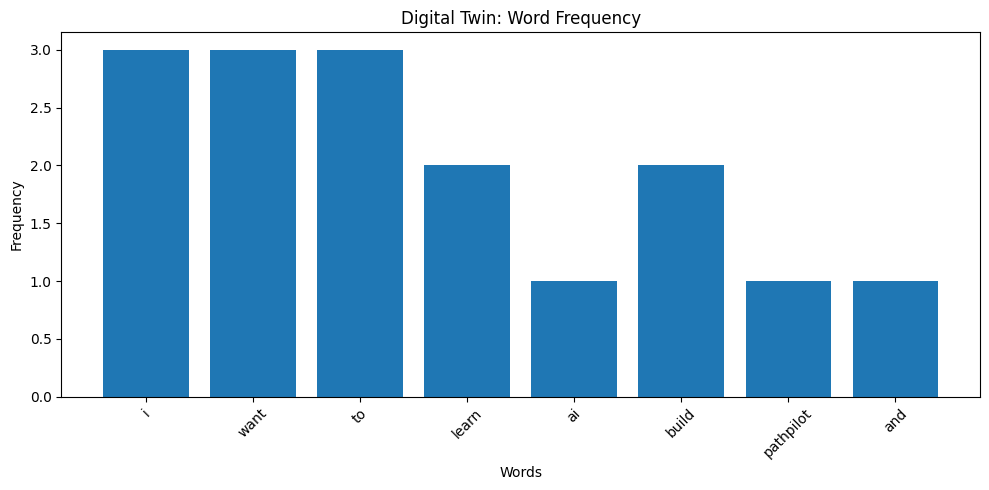

ERROR:DigitalTwin:Input validation or processing failed.
Traceback (most recent call last):
  File "/tmp/ipykernel_2084/2250369308.py", line 70, in process
    raise ValueError("input_data cannot be empty.")
ValueError: input_data cannot be empty.
ERROR:DigitalTwin:Input validation or processing failed.
Traceback (most recent call last):
  File "/tmp/ipykernel_2084/2250369308.py", line 67, in process
    raise TypeError("input_data must be a list of strings.")
TypeError: input_data must be a list of strings.
ERROR:DigitalTwin:Input validation or processing failed.
Traceback (most recent call last):
  File "/tmp/ipykernel_2084/2250369308.py", line 73, in process
    raise TypeError("Every item in input_data must be a string.")
TypeError: Every item in input_data must be a string.


Passed!

TEST 4: Empty input
Passed: input_data cannot be empty.

TEST 5: Incorrect input type
Passed: input_data must be a list of strings.

TEST 6: Invalid list item
Passed: Every item in input_data must be a string.

TEST 7: Invalid configuration
Passed: embedding_dim must be greater than zero.

TEST 8: Unknown word
Passed: Word 'spaceship' is not in the vocabulary.

TEST 9: Similarity before processing
Passed: Process some text before comparing word vectors.

All 9 tests passed!


In [7]:

import re
import logging
from collections import Counter
from typing import List, Dict, Any

import numpy as np
import matplotlib.pyplot as plt


# Configure logging for debugging
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)
logger = logging.getLogger("DigitalTwin")


class ProductionSystem:
    """
    Digital Twin Text Analysis Prototype

    Features:
    - Text validation and tokenization
    - Word frequency and neighboring-word analysis
    - Reproducible demonstration vectors
    - Cosine similarity calculations
    - Visualization of word frequencies
    - Logging and error handling

    Note:
    The generated vectors are random, not trained semantic embeddings.
    """

    def __init__(self, embedding_dim: int = 10, seed: int = 42):
        """Initialize and validate configuration."""

        if not isinstance(embedding_dim, int) or isinstance(embedding_dim, bool):
            raise TypeError("embedding_dim must be an integer.")

        if embedding_dim <= 0:
            raise ValueError("embedding_dim must be greater than zero.")

        if not isinstance(seed, int) or isinstance(seed, bool):
            raise TypeError("seed must be an integer.")

        self.embedding_dim = embedding_dim
        self.seed = seed
        self.results = None
        self.embeddings = {}

        logger.info(
            "System initialized: embedding dimension=%d",
            embedding_dim
        )

    def process(self, input_data: List[str]) -> Dict[str, Any]:
        """
        Process text and return word counts, co-occurrence pairs,
        demonstration vectors, and basic metadata.
        """

        logger.info("Starting text processing.")

        try:
            # Validate input
            if not isinstance(input_data, list):
                raise TypeError("input_data must be a list of strings.")

            if not input_data:
                raise ValueError("input_data cannot be empty.")

            if not all(isinstance(item, str) for item in input_data):
                raise TypeError("Every item in input_data must be a string.")

            # Tokenize each sentence separately
            sentences = [
                re.findall(r"\b\w+\b", sentence.lower())
                for sentence in input_data
            ]

            all_words = [
                word
                for sentence in sentences
                for word in sentence
            ]

            if not all_words:
                raise ValueError(
                    "Input contains no usable words. Please provide text."
                )

            # Word frequency
            word_counts = Counter(all_words)

            # Neighboring pairs within each sentence
            pair_counts = Counter()
            for words in sentences:
                for i in range(len(words) - 1):
                    pair_counts[(words[i], words[i + 1])] += 1

            # Build vocabulary and reproducible demonstration vectors
            vocabulary = sorted(set(all_words))
            rng = np.random.default_rng(self.seed)

            self.embeddings = {
                word: rng.normal(
                    loc=0.0,
                    scale=1.0,
                    size=self.embedding_dim
                )
                for word in vocabulary
            }

            self.results = {
                "sentences_processed": len(input_data),
                "vocabulary_size": len(vocabulary),
                "embedding_dimension": self.embedding_dim,
                "word_counts": dict(word_counts),
                "co_occurrence": {
                    f"{first} -> {second}": count
                    for (first, second), count in pair_counts.items()
                },
                "embeddings": {
                    word: vector.round(3).tolist()
                    for word, vector in self.embeddings.items()
                },
                "embedding_type": "random demonstration vectors"
            }

            logger.info(
                "Processing completed: %d words, %d unique words.",
                len(all_words),
                len(vocabulary)
            )

            return self.results

        except (TypeError, ValueError):
            logger.exception("Input validation or processing failed.")
            raise

        except Exception:
            logger.exception("Unexpected processing error.")
            raise

    def cosine_similarity(self, word1: str, word2: str) -> float:
        """
        Calculate cosine similarity between two available word vectors.

        Scores near 1 indicate similar vector directions;
        scores near 0 indicate perpendicular directions;
        scores near -1 indicate opposite directions.
        """

        if not self.embeddings:
            raise RuntimeError(
                "Process some text before comparing word vectors."
            )

        if not isinstance(word1, str) or not isinstance(word2, str):
            raise TypeError("Both words must be strings.")

        word1 = word1.lower()
        word2 = word2.lower()

        if word1 not in self.embeddings:
            raise ValueError(f"Word '{word1}' is not in the vocabulary.")

        if word2 not in self.embeddings:
            raise ValueError(f"Word '{word2}' is not in the vocabulary.")

        vector1 = self.embeddings[word1]
        vector2 = self.embeddings[word2]

        denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)

        if denominator == 0:
            raise ValueError("Cannot compare a zero-length vector.")

        score = np.dot(vector1, vector2) / denominator
        return float(score)

    def visualize(self):
        """Plot word frequencies from the most recent processing run."""

        if self.results is None:
            raise RuntimeError(
                "Process text before creating a visualization."
            )

        counts = self.results["word_counts"]
        words = list(counts.keys())
        frequencies = list(counts.values())

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(words, frequencies)
        ax.set_title("Digital Twin: Word Frequency")
        ax.set_xlabel("Words")
        ax.set_ylabel("Frequency")
        ax.tick_params(axis="x", rotation=45)

        plt.tight_layout()
        plt.show()

        logger.info("Word frequency visualization displayed.")


# -----------------------------
# TESTS AND EXAMPLE USAGE
# -----------------------------

system = ProductionSystem(embedding_dim=10, seed=42)

sample_data = [
    "I want to learn AI",
    "I want to build PathPilot",
    "I want to learn and build"
]

# Test 1: Process valid text
result = system.process(sample_data)

print("\nTEST 1: Text processing")
print("Sentences processed:", result["sentences_processed"])
print("Vocabulary size:", result["vocabulary_size"])
print("Word counts:", result["word_counts"])
print("Neighboring pairs:", result["co_occurrence"])
print("Example vector for 'learn':", result["embeddings"]["learn"])
assert result["word_counts"]["i"] == 3
assert result["word_counts"]["learn"] == 2
print("Passed!")

# Test 2: Cosine similarity calculation
print("\nTEST 2: Cosine similarity")
score = system.cosine_similarity("learn", "build")
print("Similarity between 'learn' and 'build':", round(score, 3))
assert -1.0 <= score <= 1.0
print("Passed!")

# Test 3: Visualization
print("\nTEST 3: Visualization")
system.visualize()
print("Passed!")

# Test 4: Empty input
print("\nTEST 4: Empty input")
try:
    system.process([])
except ValueError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected ValueError")

# Test 5: Incorrect input type
print("\nTEST 5: Incorrect input type")
try:
    system.process("This should be a list")
except TypeError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected TypeError")

# Test 6: Invalid item
print("\nTEST 6: Invalid list item")
try:
    system.process(["valid text", 123])
except TypeError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected TypeError")

# Test 7: Invalid embedding dimension
print("\nTEST 7: Invalid configuration")
try:
    ProductionSystem(embedding_dim=0)
except ValueError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected ValueError")

# Test 8: Unknown word
print("\nTEST 8: Unknown word")
try:
    system.cosine_similarity("learn", "spaceship")
except ValueError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected ValueError")

# Test 9: Similarity before processing
print("\nTEST 9: Similarity before processing")
new_system = ProductionSystem()
try:
    new_system.cosine_similarity("learn", "build")
except RuntimeError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected RuntimeError")

print("\nAll 9 tests passed!")


---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

In [8]:

import re
import logging
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)
logger = logging.getLogger("PathPilotEmbeddings")

# Small learning dataset.
# Later, you can expand this with more relevant text.
sentences = [
    "I want to learn artificial intelligence",
    "I want to build PathPilot",
    "Learning helps people achieve goals",
    "Artificial intelligence can support learning",
    "PathPilot helps people plan their goals",
    "People can learn new skills",
    "Building skills helps career growth",
    "Career goals require planning and learning",
    "Artificial intelligence supports personal growth",
    "I want to develop useful skills",
    "Planning goals helps personal development",
    "Learning new skills supports career development",
    "PathPilot supports learning and personal goals",
    "People use artificial intelligence to learn",
    "Personal growth requires effort and planning"
]


def prepare_data(sentences):
    """
    Clean and tokenize sentences.
    Build a vocabulary, word counts, and word-context pairs.
    """

    if not isinstance(sentences, list):
        raise TypeError("sentences must be a list of strings.")

    if not sentences:
        raise ValueError("sentences cannot be empty.")

    if not all(isinstance(s, str) for s in sentences):
        raise TypeError("Every sentence must be a string.")

    tokenized_sentences = []

    for sentence in sentences:
        tokens = re.findall(r"\b[a-z]+\b", sentence.lower())

        if tokens:
            tokenized_sentences.append(tokens)

    if not tokenized_sentences:
        raise ValueError("No usable words were found.")

    word_counts = Counter(
        word
        for sentence in tokenized_sentences
        for word in sentence
    )

    vocabulary = sorted(word_counts.keys())

    word_to_id = {
        word: index
        for index, word in enumerate(vocabulary)
    }

    # Collect neighboring words for training
    # A window of 2 means up to two words on either side.
    training_pairs = []

    window_size = 2

    for tokens in tokenized_sentences:
        for center_index, center_word in enumerate(tokens):
            start = max(0, center_index - window_size)
            end = min(len(tokens), center_index + window_size + 1)

            for context_index in range(start, end):
                if context_index != center_index:
                    context_word = tokens[context_index]
                    training_pairs.append((center_word, context_word))

    # Build global word co-occurrence counts for GloVe
    co_occurrence = defaultdict(float)

    for center_word, context_word in training_pairs:
        co_occurrence[(center_word, context_word)] += 1.0

    logger.info("Data preparation completed.")

    return {
        "sentences": tokenized_sentences,
        "word_counts": word_counts,
        "vocabulary": vocabulary,
        "word_to_id": word_to_id,
        "training_pairs": training_pairs,
        "co_occurrence": dict(co_occurrence)
    }


# Prepare the dataset
data = prepare_data(sentences)

print("Sentences:", len(data["sentences"]))
print("Vocabulary size:", len(data["vocabulary"]))
print("Training pairs:", len(data["training_pairs"]))
print("Sample vocabulary:", data["vocabulary"][:15])

print("\nSample training pairs:")
print(data["training_pairs"][:10])

print("\nSample co-occurrence counts:")
for pair, count in list(data["co_occurrence"].items())[:10]:
    print(f"{pair[0]} -> {pair[1]}: {count}")

# Basic tests
assert len(data["sentences"]) > 0
assert "learning" in data["word_to_id"]
assert "pathpilot" in data["word_to_id"]
assert len(data["training_pairs"]) > 0
assert len(data["co_occurrence"]) > 0

print("\nAll Step 1 tests passed!")


Sentences: 15
Vocabulary size: 33
Training pairs: 242
Sample vocabulary: ['achieve', 'and', 'artificial', 'build', 'building', 'can', 'career', 'develop', 'development', 'effort', 'goals', 'growth', 'helps', 'i', 'intelligence']

Sample training pairs:
[('i', 'want'), ('i', 'to'), ('want', 'i'), ('want', 'to'), ('want', 'learn'), ('to', 'i'), ('to', 'want'), ('to', 'learn'), ('to', 'artificial'), ('learn', 'want')]

Sample co-occurrence counts:
i -> want: 3.0
i -> to: 3.0
want -> i: 3.0
want -> to: 3.0
want -> learn: 1.0
to -> i: 3.0
to -> want: 3.0
to -> learn: 2.0
to -> artificial: 2.0
learn -> want: 1.0

All Step 1 tests passed!


Word2Vec training complete!
Vocabulary size: 33
Vector dimensions: 20
Initial loss: 2.695
Final loss: 1.2121


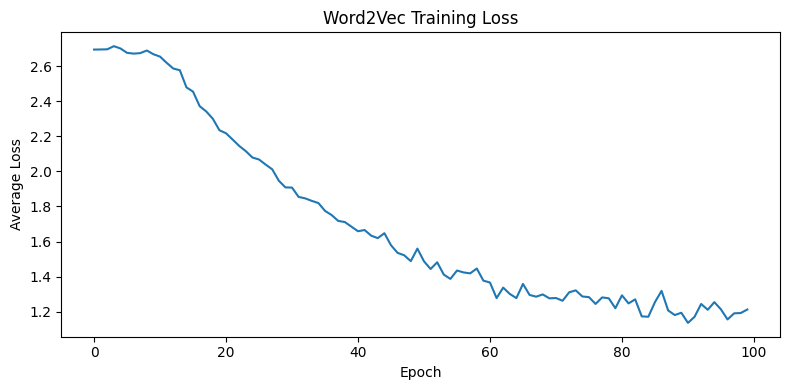


Example vector for 'learning':
[-0.284  0.065  0.784 -0.657 -0.271 -1.35  -0.675  0.737 -1.121 -0.147]

Similarity between 'learning' and 'goals': 0.463

All Step 2 tests passed!


In [9]:

# STEP 2: Word2Vec using Skip-gram with Negative Sampling (SGNS)

class SimpleWord2Vec:
    """
    A small Skip-gram with Negative Sampling implementation.

    Learns vectors from positive word-context pairs and randomly
    sampled negative pairs using gradient descent.
    """

    def __init__(
        self,
        vocab_size,
        embedding_dim=20,
        learning_rate=0.025,
        seed=42
    ):
        if vocab_size < 2:
            raise ValueError("vocab_size must be at least 2.")
        if embedding_dim <= 0:
            raise ValueError("embedding_dim must be positive.")
        if learning_rate <= 0:
            raise ValueError("learning_rate must be positive.")

        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.learning_rate = learning_rate

        rng = np.random.default_rng(seed)

        # Input and output embeddings
        self.input_vectors = rng.normal(
            0, 0.1, (vocab_size, embedding_dim)
        )
        self.output_vectors = np.zeros(
            (vocab_size, embedding_dim)
        )

    @staticmethod
    def sigmoid(x):
        # Clip values to avoid numerical overflow
        x = np.clip(x, -15, 15)
        return 1 / (1 + np.exp(-x))

    def train(self, pairs, word_to_id, epochs=100, negatives=3):
        if not pairs:
            raise ValueError("Training pairs cannot be empty.")
        if epochs <= 0 or negatives <= 0:
            raise ValueError("epochs and negatives must be positive.")

        rng = np.random.default_rng(123)
        ids = [
            (word_to_id[center], word_to_id[context])
            for center, context in pairs
        ]

        # Sample negatives more often for frequent words
        counts = np.zeros(self.vocab_size)
        for word_id in word_to_id.values():
            counts[word_id] = 1

        for center, context in pairs:
            counts[word_to_id[center]] += 1
            counts[word_to_id[context]] += 1

        probabilities = counts ** 0.75
        probabilities /= probabilities.sum()

        losses = []

        for epoch in range(epochs):
            rng.shuffle(ids)
            total_loss = 0.0

            for center_id, context_id in ids:
                # Positive pair: center and real context
                v = self.input_vectors[center_id].copy()
                u = self.output_vectors[context_id].copy()

                score = np.dot(v, u)
                prediction = self.sigmoid(score)

                total_loss -= np.log(prediction + 1e-10)

                grad = prediction - 1
                self.input_vectors[center_id] -= (
                    self.learning_rate * grad * u
                )
                self.output_vectors[context_id] -= (
                    self.learning_rate * grad * v
                )

                # Negative pairs: center and randomly sampled words
                for _ in range(negatives):
                    negative_id = rng.choice(
                        self.vocab_size, p=probabilities
                    )

                    if negative_id == context_id:
                        continue

                    v = self.input_vectors[center_id].copy()
                    u = self.output_vectors[negative_id].copy()

                    score = np.dot(v, u)
                    prediction = self.sigmoid(score)

                    total_loss -= np.log(1 - prediction + 1e-10)

                    grad = prediction
                    self.input_vectors[center_id] -= (
                        self.learning_rate * grad * u
                    )
                    self.output_vectors[negative_id] -= (
                        self.learning_rate * grad * v
                    )

            losses.append(total_loss / len(ids))

            if (epoch + 1) % 25 == 0:
                logger.info(
                    "Word2Vec epoch %d/%d; average loss %.4f",
                    epoch + 1, epochs, losses[-1]
                )

        self.losses = losses
        # Common practice: use the input embeddings as word vectors
        self.embeddings = self.input_vectors.copy()

        return losses

    def similarity(self, word1, word2, word_to_id):
        if word1 not in word_to_id or word2 not in word_to_id:
            raise ValueError("Both words must exist in the vocabulary.")

        v1 = self.embeddings[word_to_id[word1]]
        v2 = self.embeddings[word_to_id[word2]]

        denominator = np.linalg.norm(v1) * np.linalg.norm(v2)
        if denominator == 0:
            return 0.0

        return float(np.dot(v1, v2) / denominator)


# Build and train the model
word2vec = SimpleWord2Vec(
    vocab_size=len(data["vocabulary"]),
    embedding_dim=20,
    learning_rate=0.025,
    seed=42
)

losses = word2vec.train(
    pairs=data["training_pairs"],
    word_to_id=data["word_to_id"],
    epochs=100,
    negatives=3
)

print("Word2Vec training complete!")
print("Vocabulary size:", word2vec.vocab_size)
print("Vector dimensions:", word2vec.embedding_dim)
print("Initial loss:", round(losses[0], 4))
print("Final loss:", round(losses[-1], 4))

# Plot the training loss
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.title("Word2Vec Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.tight_layout()
plt.show()

# Inspect vectors and compare two words
learn_id = data["word_to_id"]["learning"]
print("\nExample vector for 'learning':")
print(np.round(word2vec.embeddings[learn_id][:10], 3))

score = word2vec.similarity(
    "learning", "goals", data["word_to_id"]
)
print("\nSimilarity between 'learning' and 'goals':", round(score, 3))

# Basic tests
assert word2vec.embeddings.shape == (33, 20)
assert len(losses) == 100
assert np.isfinite(word2vec.embeddings).all()
assert -1 <= score <= 1

print("\nAll Step 2 tests passed!")


GloVe training complete!
Vocabulary size: 33
Vector dimensions: 20
Initial loss: 0.0196
Final loss: 0.0025


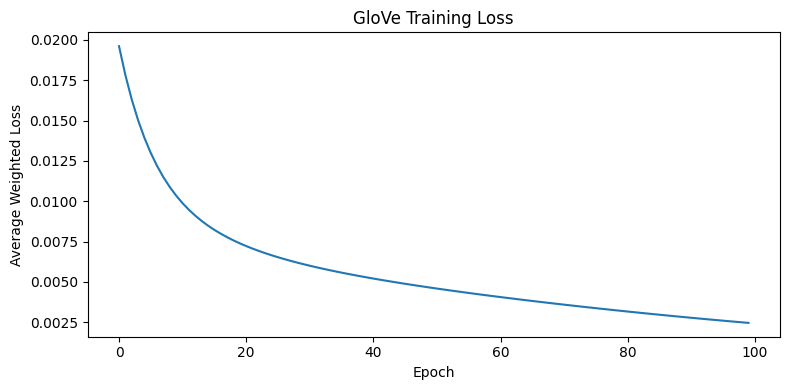


Example vector for 'learning':
[ 0.179 -0.215  0.249  0.141  0.245  0.149 -0.302  0.063 -0.142 -0.115]

Similarity between 'learning' and 'goals': -0.089

All Step 3 tests passed!


In [10]:

# STEP 3: GloVe-style embeddings using co-occurrence statistics

class SimpleGloVe:
    """
    A simplified GloVe model.

    Learns word and context vectors by fitting their dot products,
    plus biases, to the logarithm of word co-occurrence counts.
    """

    def __init__(
        self,
        vocabulary,
        embedding_dim=20,
        learning_rate=0.03,
        x_max=10,
        alpha=0.75,
        seed=42
    ):
        if not vocabulary:
            raise ValueError("Vocabulary cannot be empty.")
        if embedding_dim <= 0:
            raise ValueError("embedding_dim must be positive.")
        if learning_rate <= 0:
            raise ValueError("learning_rate must be positive.")
        if x_max <= 0 or not 0 < alpha <= 1:
            raise ValueError("x_max must be positive and alpha in (0, 1].")

        self.vocabulary = vocabulary
        self.word_to_id = {
            word: i for i, word in enumerate(vocabulary)
        }
        self.embedding_dim = embedding_dim
        self.learning_rate = learning_rate
        self.x_max = x_max
        self.alpha = alpha

        rng = np.random.default_rng(seed)
        size = len(vocabulary)

        self.word_vectors = rng.normal(
            0, 0.1, (size, embedding_dim)
        )
        self.context_vectors = rng.normal(
            0, 0.1, (size, embedding_dim)
        )
        self.word_bias = np.zeros(size)
        self.context_bias = np.zeros(size)

    def train(self, co_occurrence, epochs=100):
        if not co_occurrence:
            raise ValueError("Co-occurrence data cannot be empty.")
        if epochs <= 0:
            raise ValueError("epochs must be positive.")

        # Keep only valid, positive co-occurrence counts
        pairs = []
        for (word, context), count in co_occurrence.items():
            if word not in self.word_to_id:
                continue
            if context not in self.word_to_id:
                continue
            if not np.isfinite(count) or count <= 0:
                raise ValueError("Co-occurrence counts must be positive.")

            pairs.append((
                self.word_to_id[word],
                self.word_to_id[context],
                float(count)
            ))

        if not pairs:
            raise ValueError("No valid co-occurrence pairs were found.")

        losses = []

        for epoch in range(epochs):
            total_loss = 0.0

            for word_id, context_id, count in pairs:
                # GloVe target: log of the co-occurrence count
                target = np.log(count)

                # Frequent co-occurrences receive more weight,
                # up to a maximum of 1.
                weight = min(
                    (count / self.x_max) ** self.alpha,
                    1.0
                )

                word_vector = self.word_vectors[word_id].copy()
                context_vector = self.context_vectors[context_id].copy()

                prediction = (
                    np.dot(word_vector, context_vector)
                    + self.word_bias[word_id]
                    + self.context_bias[context_id]
                )

                error = prediction - target
                total_loss += 0.5 * weight * error ** 2

                # Gradient updates
                grad = weight * error

                self.word_vectors[word_id] -= (
                    self.learning_rate * grad * context_vector
                )
                self.context_vectors[context_id] -= (
                    self.learning_rate * grad * word_vector
                )
                self.word_bias[word_id] -= self.learning_rate * grad
                self.context_bias[context_id] -= self.learning_rate * grad

            average_loss = total_loss / len(pairs)
            losses.append(average_loss)

            if (epoch + 1) % 25 == 0:
                logger.info(
                    "GloVe epoch %d/%d; average loss %.4f",
                    epoch + 1, epochs, average_loss
                )

        self.losses = losses

        # Combine word and context vectors for final representations
        self.embeddings = self.word_vectors + self.context_vectors

        return losses

    def similarity(self, word1, word2):
        if not hasattr(self, "embeddings"):
            raise RuntimeError("Train the GloVe model before comparing words.")

        if word1 not in self.word_to_id or word2 not in self.word_to_id:
            raise ValueError("Both words must exist in the vocabulary.")

        v1 = self.embeddings[self.word_to_id[word1]]
        v2 = self.embeddings[self.word_to_id[word2]]

        denominator = np.linalg.norm(v1) * np.linalg.norm(v2)

        if denominator == 0:
            return 0.0

        return float(np.dot(v1, v2) / denominator)


# Train GloVe using the counts from Step 1
glove = SimpleGloVe(
    vocabulary=data["vocabulary"],
    embedding_dim=20,
    learning_rate=0.03,
    seed=42
)

glove_losses = glove.train(
    co_occurrence=data["co_occurrence"],
    epochs=100
)

print("GloVe training complete!")
print("Vocabulary size:", len(glove.vocabulary))
print("Vector dimensions:", glove.embedding_dim)
print("Initial loss:", round(glove_losses[0], 4))
print("Final loss:", round(glove_losses[-1], 4))

# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(glove_losses)
plt.title("GloVe Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Weighted Loss")
plt.tight_layout()
plt.show()

# Inspect a learned vector and compare words
learning_id = glove.word_to_id["learning"]
print("\nExample vector for 'learning':")
print(np.round(glove.embeddings[learning_id][:10], 3))

score = glove.similarity("learning", "goals")
print("\nSimilarity between 'learning' and 'goals':", round(score, 3))

# Basic tests
assert glove.embeddings.shape == (33, 20)
assert len(glove_losses) == 100
assert np.isfinite(glove.embeddings).all()
assert -1 <= score <= 1

print("\nAll Step 3 tests passed!")


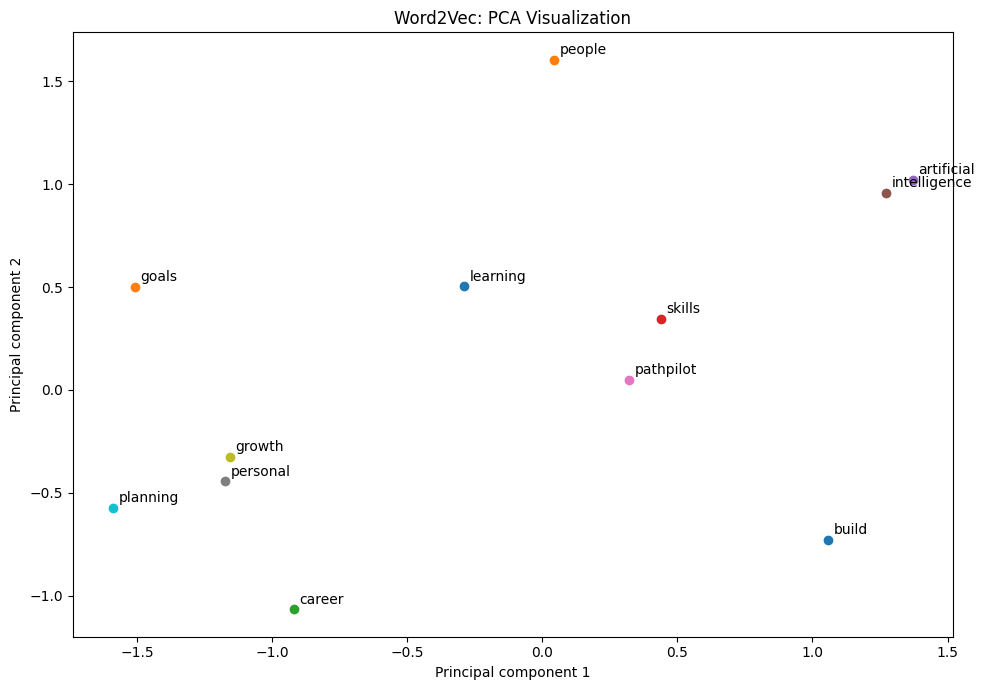

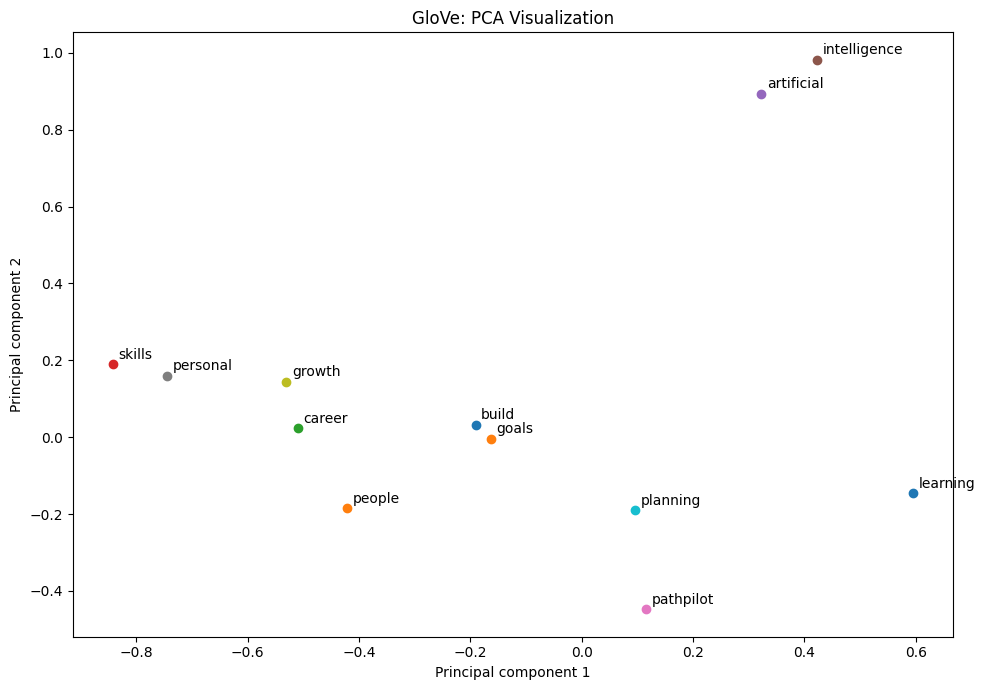

Word similarity comparison
------------------------------------------------------------
Word pair                          Word2Vec        GloVe
learning / goals                      0.463       -0.089
career / skills                       0.180        0.630
artificial / intelligence             0.581        0.908
pathpilot / goals                     0.192        0.131

All Step 4 tests passed!


In [11]:

# STEP 4: Compare Word2Vec and GloVe embeddings with PCA

def reduce_to_2d(embeddings):
    """Reduce vectors to two dimensions using NumPy-based PCA."""

    embeddings = np.asarray(embeddings, dtype=float)

    if embeddings.ndim != 2:
        raise ValueError("Embeddings must be a 2D array.")
    if embeddings.shape[0] < 2 or embeddings.shape[1] < 2:
        raise ValueError("PCA needs at least 2 words and 2 dimensions.")
    if not np.isfinite(embeddings).all():
        raise ValueError("Embeddings contain non-finite values.")

    # Center each dimension
    centered = embeddings - embeddings.mean(axis=0)

    # Singular value decomposition
    _, _, right_vectors = np.linalg.svd(
        centered, full_matrices=False
    )

    # Project onto the first two principal components
    reduced = centered @ right_vectors[:2].T

    return reduced


def plot_embeddings(model_vectors, vocabulary, title, words_to_show=None):
    """Plot selected word vectors in two dimensions."""

    coordinates = reduce_to_2d(model_vectors)

    if words_to_show is None:
        words_to_show = vocabulary

    indices = [
        vocabulary.index(word)
        for word in words_to_show
        if word in vocabulary
    ]

    if not indices:
        raise ValueError("No requested words were found in the vocabulary.")

    plt.figure(figsize=(10, 7))

    for index in indices:
        x, y = coordinates[index]
        word = vocabulary[index]

        plt.scatter(x, y)
        plt.annotate(
            word,
            (x, y),
            xytext=(4, 4),
            textcoords="offset points"
        )

    plt.title(title)
    plt.xlabel("Principal component 1")
    plt.ylabel("Principal component 2")
    plt.tight_layout()
    plt.show()

    return coordinates


# Use the same set of words for both models
selected_words = [
    "learning", "goals", "career", "skills",
    "artificial", "intelligence", "pathpilot",
    "personal", "growth", "planning",
    "build", "people"
]

word2vec_coordinates = plot_embeddings(
    word2vec.embeddings,
    data["vocabulary"],
    "Word2Vec: PCA Visualization",
    selected_words
)

glove_coordinates = plot_embeddings(
    glove.embeddings,
    data["vocabulary"],
    "GloVe: PCA Visualization",
    selected_words
)

# Compare cosine similarity for several word pairs
comparison_pairs = [
    ("learning", "goals"),
    ("career", "skills"),
    ("artificial", "intelligence"),
    ("pathpilot", "goals")
]

print("Word similarity comparison")
print("-" * 60)
print(f"{'Word pair':<30} {'Word2Vec':>12} {'GloVe':>12}")

for word1, word2 in comparison_pairs:
    w2v_score = word2vec.similarity(
        word1, word2, data["word_to_id"]
    )
    glove_score = glove.similarity(word1, word2)

    print(
        f"{word1 + ' / ' + word2:<30} "
        f"{w2v_score:>12.3f} {glove_score:>12.3f}"
    )

# Basic tests
assert word2vec_coordinates.shape == (33, 2)
assert glove_coordinates.shape == (33, 2)
assert np.isfinite(word2vec_coordinates).all()
assert np.isfinite(glove_coordinates).all()

print("\nAll Step 4 tests passed!")


In [12]:

# STEP 5: Integration, testing, and documentation

class PathPilotEmbeddingSystem:
    """
    Integrates trained Word2Vec and GloVe models.

    Requirements:
    - Step 1 data preparation
    - Trained Word2Vec and GloVe models
    - Similarity comparison
    - Input validation and error handling

    Note: This is an educational prototype trained on a small dataset.
    It is not yet a production-ready recommendation service.
    """

    def __init__(self, data, word2vec_model, glove_model):
        if not isinstance(data, dict):
            raise TypeError("data must be a dictionary.")

        required_keys = {"vocabulary", "word_to_id"}
        if not required_keys.issubset(data):
            raise ValueError("Prepared data is missing required keys.")

        if word2vec_model is None or glove_model is None:
            raise ValueError("Both trained models are required.")

        self.data = data
        self.word2vec = word2vec_model
        self.glove = glove_model

        logger.info("PathPilot embedding system initialized.")

    def compare_words(self, word1, word2):
        """Compare two words using both embedding models."""

        if not isinstance(word1, str) or not isinstance(word2, str):
            raise TypeError("Both words must be strings.")

        word1 = word1.lower().strip()
        word2 = word2.lower().strip()

        if not word1 or not word2:
            raise ValueError("Words cannot be empty.")

        if word1 not in self.data["word_to_id"]:
            raise ValueError(f"Unknown word: '{word1}'")

        if word2 not in self.data["word_to_id"]:
            raise ValueError(f"Unknown word: '{word2}'")

        return {
            "word_pair": (word1, word2),
            "word2vec_similarity": self.word2vec.similarity(
                word1, word2, self.data["word_to_id"]
            ),
            "glove_similarity": self.glove.similarity(
                word1, word2
            )
        }

    def compare_multiple(self, word_pairs):
        """Compare a list of word pairs."""

        if not isinstance(word_pairs, list):
            raise TypeError("word_pairs must be a list.")

        return [
            self.compare_words(word1, word2)
            for word1, word2 in word_pairs
        ]

    def get_documentation(self):
        """Return a concise summary of the implementation."""

        return {
            "project": "PathPilot Embedding Prototype",
            "word2vec": "Skip-gram with negative sampling",
            "glove": "Weighted co-occurrence regression",
            "similarity": "Cosine similarity",
            "visualization": "PCA dimensionality reduction",
            "limitations": [
                "Small training dataset",
                "Simplified educational implementations",
                "No persistent storage",
                "Not evaluated for production use"
            ]
        }


# Create the integrated system
pathpilot = PathPilotEmbeddingSystem(
    data=data,
    word2vec_model=word2vec,
    glove_model=glove
)

# Test 1: Compare a known word pair
comparison = pathpilot.compare_words("learning", "goals")
print("TEST 1: Compare words")
print(comparison)
assert -1 <= comparison["word2vec_similarity"] <= 1
assert -1 <= comparison["glove_similarity"] <= 1
print("Passed!\n")

# Test 2: Compare multiple pairs
print("TEST 2: Multiple comparisons")
comparisons = pathpilot.compare_multiple([
    ("career", "skills"),
    ("artificial", "intelligence"),
    ("pathpilot", "goals")
])

for item in comparisons:
    print(item)

assert len(comparisons) == 3
print("Passed!\n")

# Test 3: Unknown word
print("TEST 3: Unknown word")
try:
    pathpilot.compare_words("learning", "spaceship")
except ValueError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected ValueError")

# Test 4: Empty word
print("\nTEST 4: Empty word")
try:
    pathpilot.compare_words("", "goals")
except ValueError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected ValueError")

# Test 5: Wrong input type
print("\nTEST 5: Wrong input type")
try:
    pathpilot.compare_words(123, "goals")
except TypeError as error:
    print("Passed:", error)
else:
    raise AssertionError("Expected TypeError")

# Test 6: Documentation
print("\nTEST 6: Documentation")
documentation = pathpilot.get_documentation()

for key, value in documentation.items():
    print(f"{key}: {value}")

assert "limitations" in documentation
print("\nPassed!")

print("\nAll Step 5 integration tests passed!")
logger.info("Challenge project integration tests completed.")


TEST 1: Compare words
{'word_pair': ('learning', 'goals'), 'word2vec_similarity': 0.46313186220592023, 'glove_similarity': -0.08859559572646994}
Passed!

TEST 2: Multiple comparisons
{'word_pair': ('career', 'skills'), 'word2vec_similarity': 0.17998637888553792, 'glove_similarity': 0.6297496770175223}
{'word_pair': ('artificial', 'intelligence'), 'word2vec_similarity': 0.5805143963923673, 'glove_similarity': 0.9082099895410186}
{'word_pair': ('pathpilot', 'goals'), 'word2vec_similarity': 0.19231530830954943, 'glove_similarity': 0.13145730486946391}
Passed!

TEST 3: Unknown word
Passed: Unknown word: 'spaceship'

TEST 4: Empty word
Passed: Words cannot be empty.

TEST 5: Wrong input type
Passed: Both words must be strings.

TEST 6: Documentation
project: PathPilot Embedding Prototype
word2vec: Skip-gram with negative sampling
glove: Weighted co-occurrence regression
similarity: Cosine similarity
visualization: PCA dimensionality reduction
limitations: ['Small training dataset', 'Simplif